In [1]:
import sys
import numpy
import sklearn
import joblib

print("Python:", sys.version)
print("NumPy:", numpy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

Python: 3.14.10 (tags/v3.14.10:b703b2c, Oct 25 2026, 17:36:52) [MSC v.1944 64 bit (AMD64)]
NumPy: 2.5.5
Scikit-learn: 1.9.1
Joblib: 1.6.0


In [2]:
import pandas
import vaderSentiment
import sklearn
import numpy
import joblib

print("Pandas:", pandas.__version__)
print("VADER:", vaderSentiment.__version__ if hasattr(vaderSentiment, "__version__") else "Installed")
print("NumPy:", numpy.__version__)
print("Scikit-learn:", sklearn.__version__)
print("Joblib:", joblib.__version__)

Pandas: 3.0.5
VADER: Installed
NumPy: 2.5.5
Scikit-learn: 1.9.1
Joblib: 1.6.0


In [1]:
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay
)
from sklearn.base import clone
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
print("Imports successful.")

Imports successful.


In [2]:
# Set project folders and verify input files

PROJECT_ROOT = Path(r"D:\Dynamic_AI_Chatbot_Project")
PREPARED_FOLDER = PROJECT_ROOT / "data" / "model_ready"
MODEL_FOLDER = PROJECT_ROOT / "models"
REPORT_FOLDER = PROJECT_ROOT / "outputs" / "evaluation_reports"
MODEL_FOLDER.mkdir(parents=True, exist_ok=True)
REPORT_FOLDER.mkdir(parents=True, exist_ok=True)

required_files = [
    "telecom_excel_train.csv", "telecom_excel_test.csv",
    "telecom_csv_train.csv", "telecom_csv_test.csv",
    "banking_train.csv", "banking_test.csv"
]
print("Prepared folder exists:", PREPARED_FOLDER.exists())
missing = [f for f in required_files if not (PREPARED_FOLDER / f).is_file()]
if missing:
    raise FileNotFoundError(
        "Missing model-ready files: " + ", ".join(missing) +
        ". Check the data-preparation notebook and the PROJECT_ROOT path."
    )
print("All six input files found.")

Prepared folder exists: True
All six input files found.


In [3]:
# Load train/test files and create the dataset dictionary

file_map = {
    "Telecom Excel": ("telecom_excel_train.csv", "telecom_excel_test.csv"),
    "Telecom CSV": ("telecom_csv_train.csv", "telecom_csv_test.csv"),
    "Banking": ("banking_train.csv", "banking_test.csv"),
}

loaded_data = {}
for name, (train_file, test_file) in file_map.items():
    train_df = pd.read_csv(PREPARED_FOLDER / train_file)
    test_df = pd.read_csv(PREPARED_FOLDER / test_file)

    if "target" not in train_df.columns or "target" not in test_df.columns:
        raise ValueError(f"{name}: both files must contain a 'target' column.")
    if train_df.empty or test_df.empty:
        raise ValueError(f"{name}: train or test file is empty.")
    if train_df["target"].isna().any() or test_df["target"].isna().any():
        raise ValueError(f"{name}: target contains missing values.")

    X_train = train_df.drop(columns="target")
    X_test = test_df.drop(columns="target")
    if set(X_train.columns) != set(X_test.columns):
        raise ValueError(f"{name}: train/test feature columns do not match.")
    X_test = X_test[X_train.columns]

    loaded_data[name] = {
        "X_train": X_train,
        "y_train": train_df["target"].copy(),
        "X_test": X_test,
        "y_test": test_df["target"].copy()
    }

    print(f"\n{name}")
    print("Train:", X_train.shape, "| Test:", X_test.shape)
    print("Train target counts:", train_df["target"].value_counts().to_dict())
    print("Test target counts:", test_df["target"].value_counts().to_dict())

print("\nLoaded datasets:", list(loaded_data.keys()))


Telecom Excel
Train: (5634, 27) | Test: (1409, 27)
Train target counts: {0: 4139, 1: 1495}
Test target counts: {0: 1035, 1: 374}

Telecom CSV
Train: (5634, 19) | Test: (1409, 19)
Train target counts: {'No': 4139, 'Yes': 1495}
Test target counts: {'No': 1035, 'Yes': 374}

Banking
Train: (8000, 13) | Test: (2000, 13)
Train target counts: {0: 6370, 1: 1630}
Test target counts: {0: 1592, 1: 408}

Loaded datasets: ['Telecom Excel', 'Telecom CSV', 'Banking']


In [5]:
# Standardize and validate target labels

for name, data in loaded_data.items():
    for key in ["y_train", "y_test"]:
        y = data[key]
        normalized = y.astype(str).str.strip().str.lower()
        mapping = {
            "no": 0, "yes": 1,
            "false": 0, "true": 1,
            "0": 0, "1": 1
        }
        mapped = normalized.map(mapping)
        if mapped.isna().any():
            unexpected = sorted(normalized[mapped.isna()].unique().tolist())
            raise ValueError(f"{name} {key}: unexpected labels {unexpected}")
        data[key] = mapped.astype(int)
    if set(data["y_train"].unique()) != {0, 1}:
        raise ValueError(f"{name}: training target must contain both 0 and 1.")
    if set(data["y_test"].unique()) != {0, 1}:
        raise ValueError(f"{name}: test target must contain both 0 and 1.")
    print(f"{name}: target validated (0 = negative class, 1 = positive class).")

Telecom Excel: target validated (0 = negative class, 1 = positive class).
Telecom CSV: target validated (0 = negative class, 1 = positive class).
Banking: target validated (0 = negative class, 1 = positive class).


In [6]:
# Inspect features and check for known leakage/identifier columns

blocked_columns = {
    "customerid", "customer_id", "surname", "churn_label",
    "churn_score", "churn_reason", "complain"
}
for name, data in loaded_data.items():
    X = data["X_train"]
    suspicious = [c for c in X.columns if c.lower() in blocked_columns]
    print(f"\n{name}: {X.shape[1]} features")
    print("Numeric:", X.select_dtypes(include="number").columns.tolist())
    print("Categorical:", X.select_dtypes(exclude="number").columns.tolist())
    print("Potentially excluded columns:", suspicious)
    if suspicious:
        raise ValueError(
            f"{name}: remove these identifier/leakage columns in the data-preparation notebook: {suspicious}"
        )


Telecom Excel: 27 features
Numeric: ['count', 'zip_code', 'latitude', 'longitude', 'tenure_months', 'monthly_charges', 'total_charges']
Categorical: ['country', 'state', 'city', 'lat_long', 'gender', 'senior_citizen', 'partner', 'dependents', 'phone_service', 'multiple_lines', 'internet_service', 'online_security', 'online_backup', 'device_protection', 'tech_support', 'streaming_tv', 'streaming_movies', 'contract', 'paperless_billing', 'payment_method']
Potentially excluded columns: []

Telecom CSV: 19 features
Numeric: ['seniorcitizen', 'tenure', 'monthlycharges', 'totalcharges']
Categorical: ['gender', 'partner', 'dependents', 'phoneservice', 'multiplelines', 'internetservice', 'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport', 'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling', 'paymentmethod']
Potentially excluded columns: []

Banking: 13 features
Numeric: ['creditscore', 'age', 'tenure', 'account_balance', 'numofproducts', 'hascrcard', 'isactivemem

In [7]:
# preprocessing and four classifiers

def make_preprocessor():
    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipe, make_column_selector(dtype_include=np.number)),
        ("categorical", categorical_pipe, make_column_selector(dtype_exclude=np.number))
    ])

def make_models():
    # New estimator objects are created for each dataset/model run.
    return {
        "Logistic Regression": LogisticRegression(
            max_iter=1500, class_weight="balanced", random_state=42
        ),
        "Decision Tree": DecisionTreeClassifier(
            class_weight="balanced", random_state=42
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=200, class_weight="balanced",
            random_state=42, n_jobs=-1
        ),
        "Gradient Boosting": GradientBoostingClassifier(random_state=42)
    }

print("Preprocessing and model definitions ready.")

Preprocessing and model definitions ready.


In [8]:
# evaluation metrics

def evaluate_model(pipeline, X_test, y_test):
    predictions = pipeline.predict(X_test)
    scores = {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    }
    try:
        probabilities = pipeline.predict_proba(X_test)[:, 1]
        scores["ROC AUC"] = roc_auc_score(y_test, probabilities)
    except (AttributeError, ValueError, IndexError):
        scores["ROC AUC"] = np.nan
    return scores

print("Evaluation function ready.")

Evaluation function ready.


In [9]:
# Train and compare all 12 model experiments

all_results = []
trained_models = {}
training_errors = []

for dataset_name, data in loaded_data.items():
    for model_name, estimator in make_models().items():
        print(f"Training: {dataset_name} | {model_name}")
        try:
            pipeline = Pipeline([
                ("preprocessing", make_preprocessor()),
                ("model", clone(estimator))
            ])
            pipeline.fit(data["X_train"], data["y_train"])
            metrics = evaluate_model(pipeline, data["X_test"], data["y_test"])

            all_results.append({
                "Dataset": dataset_name,
                "Model": model_name,
                **metrics
            })
            trained_models[(dataset_name, model_name)] = pipeline
            print("  Completed. F1 =", round(metrics["F1 Score"], 4))
        except Exception as error:
            training_errors.append({
                "Dataset": dataset_name,
                "Model": model_name,
                "Error": repr(error)
            })
            print("  FAILED:", repr(error))

print("\nSuccessful experiments:", len(all_results), "of 12")
print("Failed experiments:", len(training_errors))
if training_errors:
    display(pd.DataFrame(training_errors))
if len(all_results) != 12:
    print("Do not continue until the failed experiment(s) are resolved.")
else:
    print("All 12 experiments completed successfully.")

Training: Telecom Excel | Logistic Regression
  Completed. F1 = 0.614
Training: Telecom Excel | Decision Tree
  Completed. F1 = 0.5627
Training: Telecom Excel | Random Forest
  Completed. F1 = 0.6165
Training: Telecom Excel | Gradient Boosting
  Completed. F1 = 0.5935
Training: Telecom CSV | Logistic Regression
  Completed. F1 = 0.6136
Training: Telecom CSV | Decision Tree
  Completed. F1 = 0.4906
Training: Telecom CSV | Random Forest
  Completed. F1 = 0.5822
Training: Telecom CSV | Gradient Boosting
  Completed. F1 = 0.5895
Training: Banking | Logistic Regression
  Completed. F1 = 0.5056
Training: Banking | Decision Tree
  Completed. F1 = 0.4892
Training: Banking | Random Forest
  Completed. F1 = 0.6324
Training: Banking | Gradient Boosting
  Completed. F1 = 0.6122

Successful experiments: 12 of 12
Failed experiments: 0
All 12 experiments completed successfully.


In [10]:
# Build and display the comparison table

results_df = pd.DataFrame(all_results)
if results_df.empty:
    raise ValueError("No model results exist. Fix Section 8 before continuing.")

expected = ["Dataset", "Model", "Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"]
missing_columns = [c for c in expected if c not in results_df.columns]
if missing_columns:
    raise ValueError(f"Missing result columns: {missing_columns}")

results_df = results_df.sort_values(
    ["Dataset", "F1 Score"], ascending=[True, False]
).reset_index(drop=True)

display(results_df.round(4))
print("Rows:", len(results_df))
display(results_df.groupby("Dataset")["Model"].count().rename("Successful runs").to_frame())

,Dataset,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
0,Banking,Random Forest,0.8535,0.6478,0.6176,0.6324,0.8643
1,Banking,Gradient Boosting,0.8695,0.7774,0.5049,0.6122,0.8770
2,Banking,Logistic Regression,0.7115,0.3887,0.7230,0.5056,0.7798
3,Banking,Decision Tree,0.7995,0.5093,0.4706,0.4892,0.6772
4,Telecom CSV,Logistic Regression,0.7381,0.5043,0.7834,0.6136,0.8413
5,Telecom CSV,Gradient Boosting,0.8062,0.6735,0.5241,0.5895,0.8434
6,Telecom CSV,Random Forest,0.7637,0.5485,0.6203,0.5822,0.8225
7,Telecom CSV,Decision Tree,0.7317,0.4946,0.4866,0.4906,0.6537
8,Telecom Excel,Random Forest,0.7793,0.5721,0.6684,0.6165,0.8433
9,Telecom Excel,Logistic Regression,0.7537,0.5257,0.7380,0.6140,0.8294


Rows: 12


,Successful runs
Dataset,
Banking,4
Telecom CSV,4
Telecom Excel,4



Banking — Random Forest
              precision    recall  f1-score   support

     Class 0       0.90      0.91      0.91      1592
     Class 1       0.65      0.62      0.63       408

    accuracy                           0.85      2000
   macro avg       0.78      0.77      0.77      2000
weighted avg       0.85      0.85      0.85      2000



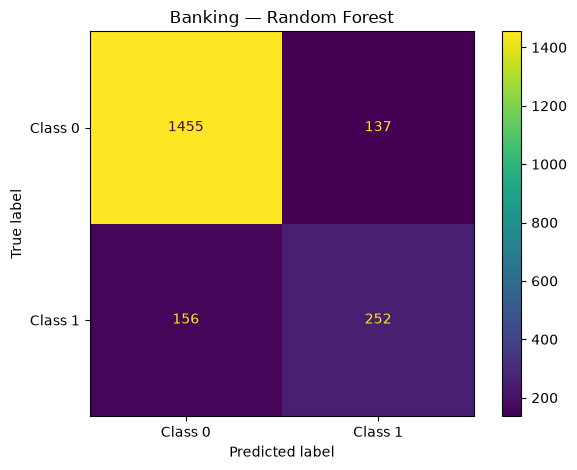


Telecom CSV — Logistic Regression
              precision    recall  f1-score   support

     Class 0       0.90      0.72      0.80      1035
     Class 1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



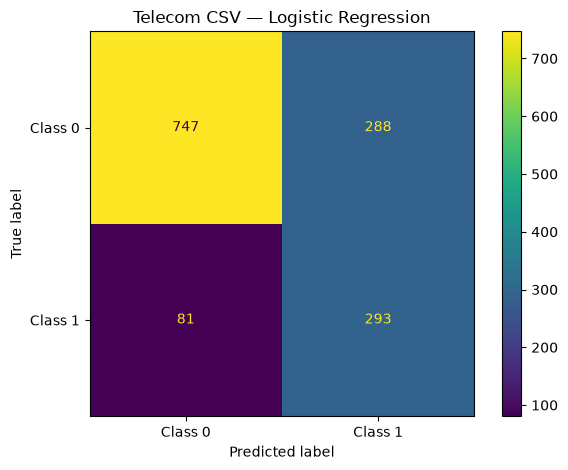


Telecom Excel — Random Forest
              precision    recall  f1-score   support

     Class 0       0.87      0.82      0.85      1035
     Class 1       0.57      0.67      0.62       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409



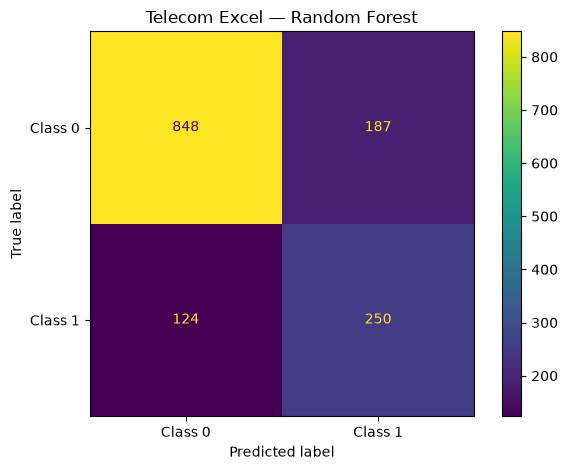

In [15]:
# reports and confusion matrices

best_models_df = results_df.groupby("Dataset", sort=False).head(1).reset_index(drop=True)

for _, row in best_models_df.iterrows():
    dataset_name = row["Dataset"]
    model_name = row["Model"]
    data = loaded_data[dataset_name]
    fitted_model = trained_models[(dataset_name, model_name)]
    predictions = fitted_model.predict(data["X_test"])

    print(f"\n{dataset_name} — {model_name}")
    print(classification_report(
        data["y_test"], predictions,
        labels=[0, 1],
        target_names=["Class 0", "Class 1"],
        zero_division=0
    ))

    cm = confusion_matrix(data["y_test"], predictions, labels=[0, 1])
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Class 0", "Class 1"]
    ).plot(values_format="d")
    plt.title(f"{dataset_name} — {model_name}")
    plt.tight_layout()
    plt.show()

In [16]:
# Save comparison reports

comparison_path = REPORT_FOLDER / "machine_learning_model_comparison.csv"
best_summary_path = REPORT_FOLDER / "best_models_by_dataset.csv"

results_df.to_csv(comparison_path, index=False)
best_models_df.to_csv(best_summary_path, index=False)

print("Saved:", comparison_path)
print("Saved:", best_summary_path)

Saved: D:\Dynamic_AI_Chatbot_Project\outputs\evaluation_reports\machine_learning_model_comparison.csv
Saved: D:\Dynamic_AI_Chatbot_Project\outputs\evaluation_reports\best_models_by_dataset.csv


In [17]:
# three best fitted model pipelines

import joblib

saved_model_paths = []
for _, row in best_models_df.iterrows():
    dataset_name = row["Dataset"]
    model_name = row["Model"]
    safe_name = dataset_name.lower().replace(" ", "_").replace("-", "_")
    model_path = MODEL_FOLDER / f"{safe_name}_best_churn_model.joblib"

    joblib.dump(trained_models[(dataset_name, model_name)], model_path)
    saved_model_paths.append(str(model_path))
    print(f"Saved {dataset_name} — {model_name}: {model_path}")

metadata = {
    "selection_metric": "F1 Score",
    "positive_class": 1,
    "models": [
        {
            "dataset": row["Dataset"],
            "model": row["Model"],
            "accuracy": float(row["Accuracy"]),
            "precision": float(row["Precision"]),
            "recall": float(row["Recall"]),
            "f1_score": float(row["F1 Score"]),
            "roc_auc": None if pd.isna(row["ROC AUC"]) else float(row["ROC AUC"])
        }
        for _, row in best_models_df.iterrows()
    ],
    "model_files": saved_model_paths
}
metadata_path = REPORT_FOLDER / "best_model_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4)
print("Metadata saved:", metadata_path)

Saved Banking — Random Forest: D:\Dynamic_AI_Chatbot_Project\models\banking_best_churn_model.joblib
Saved Telecom CSV — Logistic Regression: D:\Dynamic_AI_Chatbot_Project\models\telecom_csv_best_churn_model.joblib
Saved Telecom Excel — Random Forest: D:\Dynamic_AI_Chatbot_Project\models\telecom_excel_best_churn_model.joblib
Metadata saved: D:\Dynamic_AI_Chatbot_Project\outputs\evaluation_reports\best_model_metadata.json


In [18]:
print("Successful experiments:", len(results_df))
print("Best models selected:", len(best_models_df))
print("Comparison CSV exists:", comparison_path.is_file())
print("Best-model CSV exists:", best_summary_path.is_file())
print("Metadata JSON exists:", metadata_path.is_file())
for p in saved_model_paths:
    print(Path(p).name, "exists:", Path(p).is_file())

Successful experiments: 12
Best models selected: 3
Comparison CSV exists: True
Best-model CSV exists: True
Metadata JSON exists: True
banking_best_churn_model.joblib exists: True
telecom_csv_best_churn_model.joblib exists: True
telecom_excel_best_churn_model.joblib exists: True
